In [5]:
import polars as pl
import pandas as pd
import numpy as np
import xarray as xr
from pathlib import Path
import rioxarray
import rasterio
import datacube
from datacube.utils.cog import write_cog

https://opendatacube.readthedocs.io/en/latest/api/utilities/generate/datacube.utils.cog.write_cog.html

In [2]:
data_dir = Path("/Users/mor760/Documents/CSA-files/csv")

nrth_bf = pl.read_csv(
    data_dir / "northern-beef-dry-season-rainfall-2050s-medium-details.csv",
    null_values = "null"
)
mean_scen = nrth_bf.select(
    (pl.col("lon-idx")*0.05 + 112).alias("lon"),
    (pl.col("lat-idx")*0.05 - 44.5).alias("lat"),
    (pl.col("cmip6-2035-2064-mmm-avg (mm)") - pl.col("cmip5-2036-2065-mmm-avg (mm)")).alias("cmip6_diff_cmip5")
)
pddf = mean_scen.to_pandas()
pddf = pddf.set_index(['lat','lon'])
ds = pddf.to_xarray()
# mean_scen.head()

In [3]:
lat_array = np.linspace(-44.5,-10.0, round((-10.0 + 44.5)/0.05)+1)
lon_array = np.linspace(112.0,156.25, round((156.25-112.0)/0.05)+1)
temp = xr.DataArray(coords=[
    ("lat", lat_array),
    ("lon", lon_array)
])
da = ds.cmip6_diff_cmip5.reindex_like(temp)
da = da.isel(lat=slice(None,None,-1))
da

<xarray.DataArray 'cmip6_diff_cmip5' (lat: 691, lon: 886)> Size: 5MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(691, 886))
Coordinates:
  * lat      (lat) float64 6kB -10.0 -10.05 -10.1 -10.15 ... -44.4 -44.45 -44.5
  * lon      (lon) float64 7kB 112.0 112.0 112.1 112.2 ... 156.2 156.2 156.2

In [6]:
# ds = ds.rio.set_spatial_dims(x_dim="lon", y_dim="lat")
da.rio.write_crs("EPSG:4326", inplace=True)
da

<xarray.DataArray 'cmip6_diff_cmip5' (lat: 691, lon: 886)> Size: 5MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(691, 886))
Coordinates:
  * lat          (lat) float64 6kB -10.0 -10.05 -10.1 ... -44.4 -44.45 -44.5
  * lon          (lon) float64 7kB 112.0 112.0 112.1 112.2 ... 156.2 156.2 156.2
    spatial_ref  int64 8B 0

In [7]:
write_cog(geo_im=da,fname='nth_bf_dry_pr_diff_c6-c5.tif',overwrite=True)

/var/folders/g2/fk9yd4fs61796llh29tfgrz80000gp/T/ipykernel_61691/2027760956.py:1: ODC2DeprecationWarning: Call to deprecated function (or staticmethod) write_cog. (This method has been moved to odc-geo.)
-- Deprecated since version 1.9.0.
  write_cog(geo_im=da,fname='nth_bf_dry_pr_diff_c6-c5.tif',overwrite=True)


PosixPath('nth_bf_dry_pr_diff_c6-c5.tif')

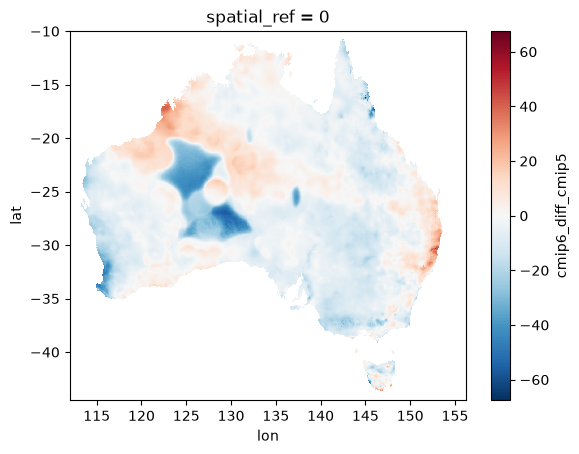

In [8]:
da.plot()